# EDA geoespacial — avisos de Agua de Hermosillo vs. red hidrográfica

¿Existe relación espacial entre la ubicación de los avisos de Agua de Hermosillo y las características de la red hidrográfica de la ciudad?

Fuentes:
- `publicaciones_aguah.csv`: tipo de evento por publicación (`restablecimiento`, `corte_programado`, `emergencia`, `pipas`, `otro`)
- `ubicaciones_aviso.csv`: lugares mencionados en las publicaciones (nombres de colonia y cruces de calles geocodificados)
- `colonias_hermosillo.gpkg`: polígonos de colonias del DCAH, puente espacial de las menciones de colonia
- `subc_hermosillo.gpkg`: capas `hl`, `dr` y `ha` del consolidado de las 4 subcuencas (INEGI 1:50 000)

**Zona de estudio:** el círculo mínimo que envuelve los cruces geocodificados, más 2 km de margen. Cubre toda el área urbana incluyendo los huecos entre asentamientos del DCAH (los 1,467 cruces caen dentro o a ≤0.6 km de la ciudad; ninguno en Bahía de Kino ni Miguel Alemán).

Nota semántica: `hl` es la red de **drenaje natural** (cauces), no la red de agua potable. La relación se interpreta hidrológicamente (proximidad a cauces y cuerpos de agua), no como fallas de tubería.

In [15]:
import geopandas as gpd
import pandas as pd
import shapely
import matplotlib.pyplot as plt
from pathlib import Path

In [16]:
DATA = Path("../../data/processed")
SUBC = DATA / "inegi/hidrografia_hermosillo/subc_hermosillo.gpkg"

publicaciones = pd.read_csv(DATA / "aguah/publicaciones_aguah.csv")
ubicaciones = pd.read_csv(DATA / "aguah/ubicaciones_aviso.csv", dtype={"colonia_id": str})

colonias = gpd.read_file(DATA / "aguah/colonias_hermosillo.gpkg")
hl = gpd.read_file(SUBC, layer="hl")
dr = gpd.read_file(SUBC, layer="dr")
ha = gpd.read_file(SUBC, layer="ha")

print(f"{len(publicaciones)} publicaciones, {len(ubicaciones)} menciones")
print(f"{len(colonias)} colonias | hl: {len(hl)}, dr: {len(dr)}, ha: {len(ha)}")

5200 publicaciones, 16261 menciones
783 colonias | hl: 46518, dr: 36, ha: 744


## Preparación

Se une cada mención con el `event_type` de su publicación. Las menciones tienen dos formas espaciales: los **cruces geocodificados** ya traen punto (`lat`/`lon`); las **menciones de colonia** se resuelven a su polígono vía `colonia_id`. Todo se reproyecta a EPSG:6372 (metros) para medir distancias.

Sobre la confianza: `match_method` indica cómo se resolvió cada mención — `colonia_con_marcador` (el texto dice "colonia X", alta confianza), `colonia_en_catalogo` (nombre suelto emparejado al catálogo, ~74% de las menciones, menor confianza), `cruce_geocodificado` y `unmatched`.

In [21]:
METRICO = 6372  # Conica Conforme de Lambert ITRF2008, metros

menciones = ubicaciones.merge(
    publicaciones[["post_id", "event_type"]], on="post_id", how="left"
)

geocodificados = menciones["match_method"] == "cruce_geocodificado"
cruces = gpd.GeoDataFrame(
    menciones[geocodificados].reset_index(drop=True),
    geometry=gpd.points_from_xy(
        menciones.loc[geocodificados, "lon"],
        menciones.loc[geocodificados, "lat"],
    ),
    crs="EPSG:4326",
).to_crs(epsg=METRICO)

menciones_colonia = menciones[menciones["location_type"] == "colonia"]

# Zona de estudio: circulo minimo que envuelve los cruces + 2 km de margen
zona = shapely.minimum_bounding_circle(cruces.union_all()).buffer(1000)
radio_km = (zona.area / 3.141592653589793) ** 0.5 / 1000

colonias_m = colonias.to_crs(epsg=METRICO)
hl_m = hl.to_crs(epsg=METRICO)
dr_m = dr.to_crs(epsg=METRICO)
ha_m = ha.to_crs(epsg=METRICO)

hl_zona = gpd.clip(hl_m, zona)
ha_zona = gpd.clip(ha_m, zona)
dr_zona = gpd.clip(dr_m, zona)

print(f"{len(cruces)} cruces geocodificados | {len(menciones_colonia)} menciones de colonia")
print(f"Zona de estudio: radio aprox. {radio_km:.1f} km")
print(f"Dentro de la zona -> hl: {len(hl_zona)}, ha: {len(ha_zona)}, dr: {len(dr_zona)}")

1467 cruces geocodificados | 14411 menciones de colonia
Zona de estudio: radio aprox. 11.8 km
Dentro de la zona -> hl: 1158, ha: 28, dr: 4


## Resumen de las menciones

Distribución de las menciones por tipo de lugar y tipo de evento de la publicación, más el desglose por método de resolución.

In [22]:
print(
    pd.crosstab(
        menciones["event_type"], menciones["location_type"], margins=True, margins_name="total"
    )
)
print()
print(menciones["match_method"].value_counts())

location_type     colonia  cruce  total
event_type                             
corte_programado     1689     64   1753
emergencia           2519    310   2829
otro                 9537   1407  10944
pipas                  56     28     84
restablecimiento      610     41    651
total               14411   1850  16261

match_method
colonia_en_catalogo     12031
colonia_con_marcador     2380
cruce_geocodificado      1467
unmatched                 383
Name: count, dtype: int64


## Mapa: cruces mencionados vs. red hidrográfica en la zona de estudio

La red `hl` dentro de la zona, diferenciando cauces de orden bajo (<4) de los colectores principales (≥4, orden de Strahler), más los cuerpos de agua `ha` y puntos de drenaje `dr`. Los cruces se colorean por `event_type`.

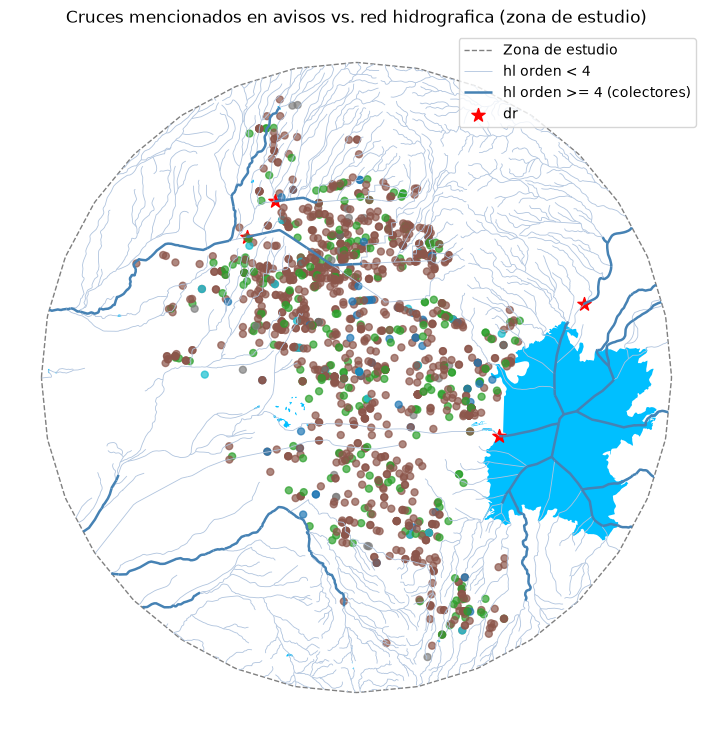

In [23]:
fig, ax = plt.subplots(figsize=(9, 9))

gpd.GeoSeries([zona], crs=hl_m.crs).boundary.plot(
    ax=ax, color="gray", linewidth=1, linestyle="--", label="Zona de estudio"
)
hl_zona[hl_zona["ORDER_1"] < 4].plot(
    ax=ax, color="lightsteelblue", linewidth=0.6, label="hl orden < 4"
)
hl_zona[hl_zona["ORDER_1"] >= 4].plot(
    ax=ax, color="steelblue", linewidth=1.8, label="hl orden >= 4 (colectores)"
)
ha_zona.plot(ax=ax, color="deepskyblue", edgecolor="none")
dr_zona.plot(ax=ax, color="red", markersize=100, marker="*", label="dr")
cruces.plot(ax=ax, column="event_type", markersize=25, legend=True, alpha=0.7)

ax.legend(loc="upper right")
ax.set_title("Cruces mencionados en avisos vs. red hidrografica (zona de estudio)")
ax.set_axis_off()
plt.show()

## Distancia a la red hidrográfica

Distancia de cada **cruce geocodificado** a la geometría más cercana de `hl`, `ha` y `dr` dentro de la zona de estudio (en metros). La zona incluye la hidrografía que el recorte a asentamientos omitía en los huecos entre colonias.

In [24]:
def distancia_a(puntos, capa, columna):
    unidos = gpd.sjoin_nearest(
        puntos, capa[["geometry"]], how="left", distance_col=columna
    )
    # sjoin_nearest duplica la fila si el punto empata entre dos geometrias
    return unidos[~unidos.index.duplicated(keep="first")].drop(columns="index_right")

cruces = cruces.pipe(distancia_a, hl_zona, "dist_hl_m")
cruces = cruces.pipe(distancia_a, ha_zona, "dist_ha_m")
cruces = cruces.pipe(distancia_a, dr_zona, "dist_dr_m")

print(cruces[["dist_hl_m", "dist_ha_m", "dist_dr_m"]].describe().round(1))

       dist_hl_m  dist_ha_m  dist_dr_m
count     1467.0     1467.0     1467.0
mean       543.9     2890.3     4110.9
std        527.2     1438.9     1748.2
min          0.1       70.1       10.7
25%        133.9     1822.4     2799.2
50%        377.8     2928.7     4103.9
75%        791.8     3954.1     5497.3
max       2361.0     6085.4     8880.4


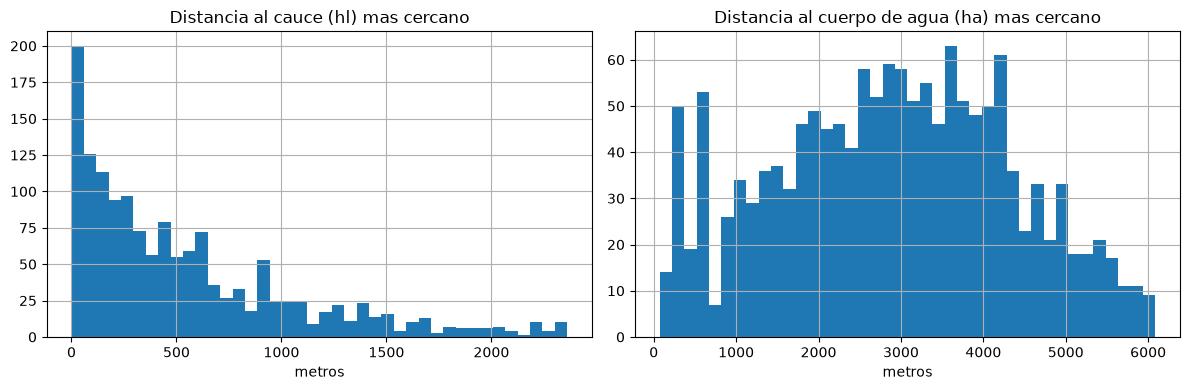

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cruces["dist_hl_m"].hist(bins=40, ax=axes[0])
axes[0].set_xlabel("metros")
axes[0].set_title("Distancia al cauce (hl) mas cercano")

cruces["dist_ha_m"].hist(bins=40, ax=axes[1])
axes[1].set_xlabel("metros")
axes[1].set_title("Distancia al cuerpo de agua (ha) mas cercano")

plt.tight_layout()
plt.show()

## Exposición por colonia

Para cada colonia de la ciudad (`locality_code == "0001"`): kilómetros de cauce `hl` que la cruzan, área de cuerpos de agua `ha` dentro, y si contiene el punto de drenaje `dr`. Se cruza con cuántas publicaciones la mencionan.

In [8]:
colonias_cd = colonias_m[colonias_m["locality_code"] == "0001"][["colonia_id", "geometry"]]

# sjoin + interseccion contra la red completa del consolidado
# (overlay descartaria los tramos lineales dentro del poligono)
pares = gpd.sjoin(hl_m[["geometry"]], colonias_cd, how="inner", predicate="intersects")
geom_colonia = pares["colonia_id"].map(colonias_cd.set_index("colonia_id")["geometry"])
tramos = pares.geometry.intersection(geom_colonia)
km_cauce = tramos.length.groupby(pares["colonia_id"]).sum() / 1000

ha_en_colonia = gpd.overlay(colonias_cd, ha_m[["geometry"]], how="intersection")
area_ha = (
    ha_en_colonia.assign(km2=lambda d: d.geometry.area / 1e6)
    .groupby("colonia_id")["km2"].sum()
)

dr_en_colonia = gpd.sjoin(
    dr_m[["geometry"]], colonias_cd, how="inner", predicate="within"
)["colonia_id"]

expo = (
    colonias_cd.set_index("colonia_id")
    .assign(km_cauce=km_cauce, area_ha_km2=area_ha)
    .fillna({"km_cauce": 0, "area_ha_km2": 0})
)
expo["tiene_dr"] = expo.index.isin(dr_en_colonia)

# Publicaciones y menciones por colonia (deduplicadas por publicacion)
expo["publicaciones"] = menciones_colonia.groupby("colonia_id")["post_id"].nunique()
expo["menciones"] = menciones_colonia.groupby("colonia_id").size()
expo[["publicaciones", "menciones"]] = expo[["publicaciones", "menciones"]].fillna(0)

print(expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]].describe().round(2))

       km_cauce  area_ha_km2  publicaciones  menciones
count    762.00       762.00         762.00     762.00
mean       0.25         0.00          18.84      18.84
std        0.69         0.01          34.92      34.92
min        0.00         0.00           0.00       0.00
25%        0.00         0.00           0.00       0.00
50%        0.00         0.00           5.00       5.00
75%        0.28         0.00          24.00      24.00
max       10.97         0.18         389.00     389.00


In [9]:
print("Correlacion de Spearman entre exposicion y menciones:")
print(
    expo[["km_cauce", "area_ha_km2", "publicaciones", "menciones"]]
    .corr(method="spearman")
    .round(2)
)
print()
print(f"Colonias con al menos un tramo de cauce: {(expo['km_cauce'] > 0).sum()} de {len(expo)}")
print(f"Colonias con cuerpo de agua: {(expo['area_ha_km2'] > 0).sum()}")
print(f"Colonias con el punto de drenaje: {expo['tiene_dr'].sum()}")

Correlacion de Spearman entre exposicion y menciones:
               km_cauce  area_ha_km2  publicaciones  menciones
km_cauce           1.00         0.08           0.04       0.04
area_ha_km2        0.08         1.00          -0.03      -0.03
publicaciones      0.04        -0.03           1.00       1.00
menciones          0.04        -0.03           1.00       1.00

Colonias con al menos un tramo de cauce: 354 de 762
Colonias con cuerpo de agua: 14
Colonias con el punto de drenaje: 1


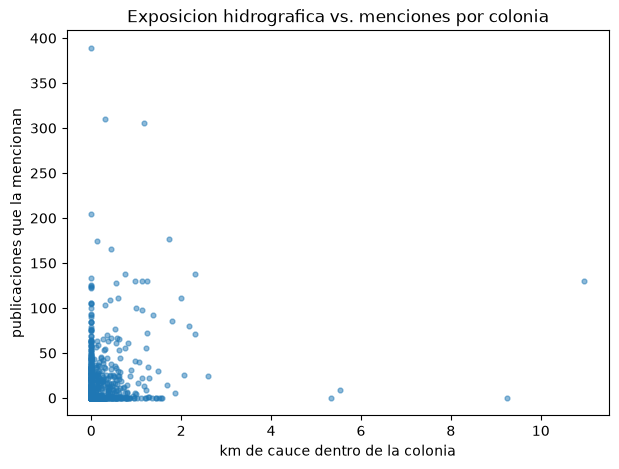

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(expo["km_cauce"], expo["publicaciones"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones que la mencionan")
ax.set_title("Exposicion hidrografica vs. menciones por colonia")
plt.show()

## Orden de Strahler (ORDER_1)

`ORDER_1` es la clasificación de Strahler del cauce a nivel subcuenca: `1` = cauces de cabecera, `5`–`7` = colectores principales; `-1` = segmentos sin clasificar. Medir distancia a "cualquier `hl`" mezcla ramalitos de drenaje con el cauce mayor — aquí se separa la distancia al colector de orden ≥4 más cercano.

In [11]:
tabla_orden = (
    hl_zona.assign(km=lambda d: d.geometry.length / 1000)
    .groupby("ORDER_1")["km"]
    .agg(segmentos="count", km_total="sum")
    .round(1)
)
print("Distribucion de ORDER_1 en la zona de estudio:")
print(tabla_orden)

colectores = hl_zona[hl_zona["ORDER_1"] >= 4][["geometry"]]
cruces = cruces.pipe(distancia_a, colectores, "dist_hl_orden4_m")

Distribucion de ORDER_1 en la zona de estudio:
         segmentos  km_total
ORDER_1                     
-1              14       4.5
 1             671     579.4
 2             357     218.1
 3             206     134.4
 4              79      59.1
 5              24      19.1
 6              12      13.8
 7              11       9.5


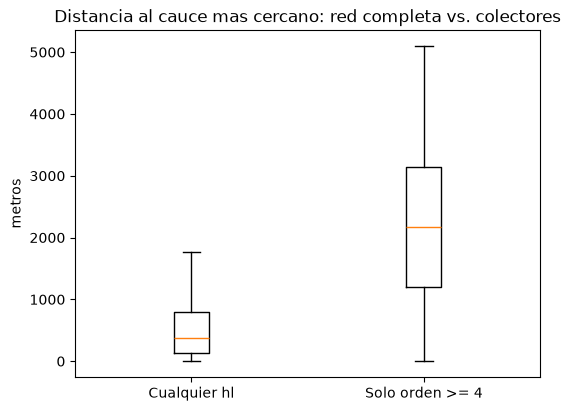

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.5))

ax.boxplot(
    [cruces["dist_hl_m"], cruces["dist_hl_orden4_m"]],
    tick_labels=["Cualquier hl", "Solo orden >= 4"],
    showfliers=False,
)
ax.set_ylabel("metros")
ax.set_title("Distancia al cauce mas cercano: red completa vs. colectores")
plt.show()

## Por tipo de evento

¿Se acercan más a la red los cruces de ciertos tipos de aviso? Y a nivel colonia: ¿las colonias con más emergencias tienen más exposición hidrográfica?

In [13]:
print(
    cruces.groupby("event_type")[["dist_hl_m", "dist_hl_orden4_m", "dist_ha_m"]]
    .median()
    .round(1)
)

                  dist_hl_m  dist_hl_orden4_m  dist_ha_m
event_type                                              
corte_programado      352.3            2179.1     2912.7
emergencia            348.4            2275.4     2806.9
otro                  380.5            2143.0     2955.4
pipas                 537.1            1723.1     2819.0
restablecimiento      483.9            2797.8     2375.5


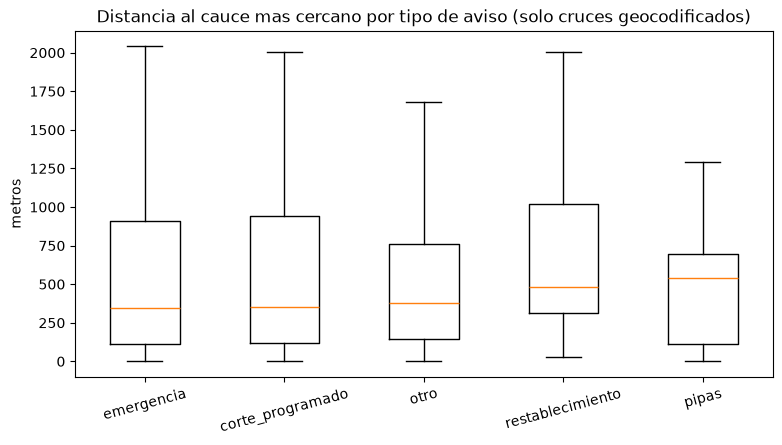

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))

orden = cruces.groupby("event_type")["dist_hl_m"].median().sort_values().index
datos = [cruces.loc[cruces["event_type"] == t, "dist_hl_m"] for t in orden]
ax.boxplot(datos, tick_labels=orden, showfliers=False)

ax.set_title("Distancia al cauce mas cercano por tipo de aviso (solo cruces geocodificados)")
ax.set_ylabel("metros")
ax.tick_params(axis="x", labelrotation=15)
plt.show()

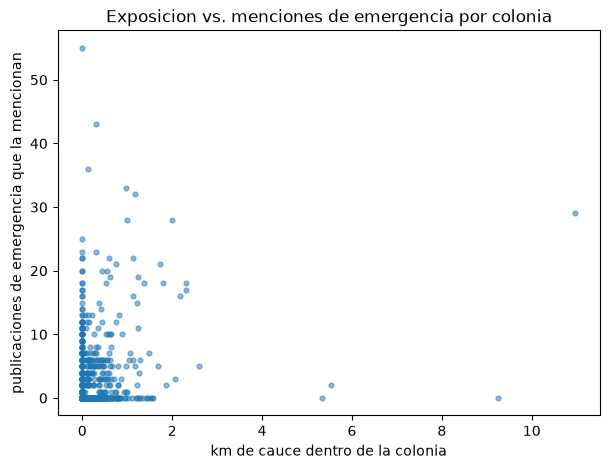

Spearman (km_cauce vs. emergencias por colonia): 0.11


In [15]:
# Emergencias por colonia vs. exposicion hidrografica
emergencias = (
    menciones_colonia[menciones_colonia["event_type"] == "emergencia"]
    .groupby("colonia_id")["post_id"].nunique()
)
expo["emergencias"] = emergencias.reindex(expo.index, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(expo["km_cauce"], expo["emergencias"], s=12, alpha=0.5)
ax.set_xlabel("km de cauce dentro de la colonia")
ax.set_ylabel("publicaciones de emergencia que la mencionan")
ax.set_title("Exposicion vs. menciones de emergencia por colonia")
plt.show()

rho = expo[["km_cauce", "emergencias"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman (km_cauce vs. emergencias por colonia): {rho:.2f}")

## Comentarios

**¿Existe relación espacial entre los avisos y la red hidrográfica? La evidencia apunta a que es débil.**

- **La zona de estudio** (círculo de ~12.8 km de radio sobre los cruces + 2 km) contiene 1,374 segmentos `hl`, 28 cuerpos de agua `ha` y 4 puntos `dr` — más del triple de red que el recorte a asentamientos (437), porque incluye la hidrografía en los huecos entre colonias.
- **Los cruces mencionados están cerca de la red, pero como todo en la ciudad.** La distancia mediana al cauce `hl` más cercano es **378 m** (IQR 134–792 m, máx. ~2.4 km); con la red completa bajó solo ~40 m respecto al recorte urbano (416 m), es decir, la hidrografía omitida en los huecos apenas movía la medición. Con una red tan densa, cualquier punto urbano queda a <1 km de algún cauce: la cercanía es propiedad de la red, no de los avisos.
- **Los avisos "operativos" son los más cercanos a la red fina.** `emergencia` (mediana 348 m) y `corte_programado` (352 m) quedan ~130–190 m más cerca que `restablecimiento` (484 m) y `pipas` (537 m) — una dirección consistente pero una diferencia pequeña para afirmar un patrón.
- **No se acercan especialmente a los colectores principales.** La mediana de distancia al cauce de orden ≥4 es ~2.1–2.8 km por tipo de evento (vs. ~350–540 m a la red fina): los avisos se reparten por la ciudad sin seguir los cauces mayores.
- **La exposición por colonia tampoco predice las menciones.** Solo 354 de 762 colonias contienen tramo de cauce (máx. ~11 km); Spearman km-cauce vs. publicaciones = **0.04**, y vs. emergencias = **0.11** — ruido, no señal.
- **Lectura alternativa:** dónde se reportan avisos parece explicarse más por la estructura urbana y las prácticas de comunicación de Agua de Hermosillo (los volantes listan tablas de colonias) que por la hidrografía.

**Limitaciones explícitas**

- `hl` es la red de drenaje **natural** de INEGI (cauces 1:50k), no la red de agua potable: cualquier cercanía se interpreta hidrológicamente, no como evidencia sobre tuberías.
- Las menciones son lugares nombrados en publicaciones de Facebook, no incidentes confirmados en campo; la cobertura refleja lo que Agua de Hermosillo decide publicar.
- Solo 4 puntos `dr` caen en la zona (de 36 del consolidado): la distancia a `dr` describe cercanía a esos pocos puntos, no a la infraestructura de drenaje en general.
- La mayoría de las menciones de colonia se resolvieron por `colonia_en_catalogo` (nombre suelto, sin el marcador "colonia"/"fracc."), el método menos seguro; 383 menciones quedaron `unmatched`.
- Una publicación lista muchas colonias a la vez (los volantes de corte traen tablas), por lo que los conteos por colonia no equivalen a número de eventos — por eso `publicaciones` y `menciones` coinciden por colonia.
- La cercanía espacial por sí sola no implica causalidad.